### Kaprekar's Magic 6174

Explores Kaprekar's routine for four-digit numbers, an elementary process that rapidly converges to the fixed point 6174. Uses histograms, convergence plots, 100x100 digit grids, animations, and a graph of value transitions to investigate why digit sorting and diagonal-neighbor collisions produce such rapid convergence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import HTML, Image
from matplotlib.animation import FuncAnimation


In [2]:
def sort_digits(n: int | str, length: int) -> str:
    return ''.join(sorted(str(n).zfill(length)))

def identical_digits(n: int, length: int) -> bool:
    digits = str(n).zfill(length)
    first_digit = digits[0]
    return all( digit == first_digit for digit in digits )

def k(n, length=4):
    ascending = sort_digits(n, length)
    descending = ascending[::-1]

    x = int(ascending)
    y = int(descending)
    
    if x > y:
        return x - y
    else:
        return y - x

def kaprekar(n, length=4, verbose=False):
    i = 0
    while True:
        m = k(n, length)
        if verbose:
            print(i, n)
        if m == n:
            return i, m
        i = i+1
        if i > 100:
            raise Exception(f"maximum iterations exceeded for kaprekar({n})")
        n = m

In [ ]:
all_numbers = np.arange(1, 10000)
valid_numbers = np.array([ num for num in all_numbers if not identical_digits(num, 4) ])
sorted_valid_numbers = np.unique(np.array([ int(sort_digits(x, 4)[::-1]) for x in valid_numbers ]))
len(sorted_valid_numbers)

705

In [4]:
assert sort_digits('1234', 4) == '1234'
assert sort_digits('4123', 4) == '1234'
assert sort_digits('999', 4) == '0999'
assert identical_digits(1111, 4)
assert not identical_digits(6174, 4)
assert identical_digits(0, 4)
assert not identical_digits(1, 4)

In [5]:
def kaprekar_iteration_counts(length=4):
    iteration_counts = []
    first_fixed_point = None
    for i in range(1, int(10**length)):
        iterations, fixed_point = kaprekar(i, length)
        if first_fixed_point is None:
            first_fixed_point = fixed_point
        if not identical_digits(i, length) and fixed_point != first_fixed_point:
            print('violation', i, iterations, fixed_point)
        iteration_counts.append(iterations)
    return iteration_counts

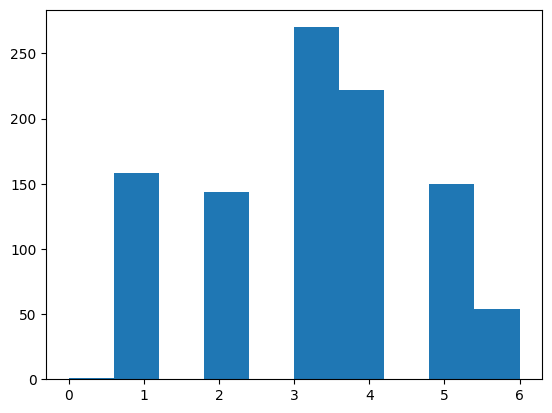

In [6]:
plt.hist(kaprekar_iteration_counts(3));

Counter({3: 2400, 7: 2184, 6: 1656, 5: 1518, 4: 1272, 2: 576, 1: 392, 0: 1})


Text(0, 0.5, 'Count of 4 Digit Numbers')

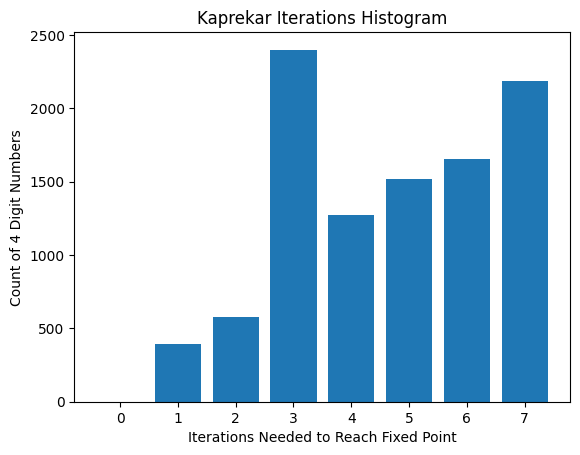

In [7]:
histogram = Counter(kaprekar_iteration_counts(4))
print(histogram)
plt.bar(list(histogram.keys()), list(histogram.values()))
plt.title("Kaprekar Iterations Histogram")
plt.xlabel("Iterations Needed to Reach Fixed Point")
plt.ylabel("Count of 4 Digit Numbers")

In [8]:
np.mean(kaprekar_iteration_counts(4))

4.665066506650665

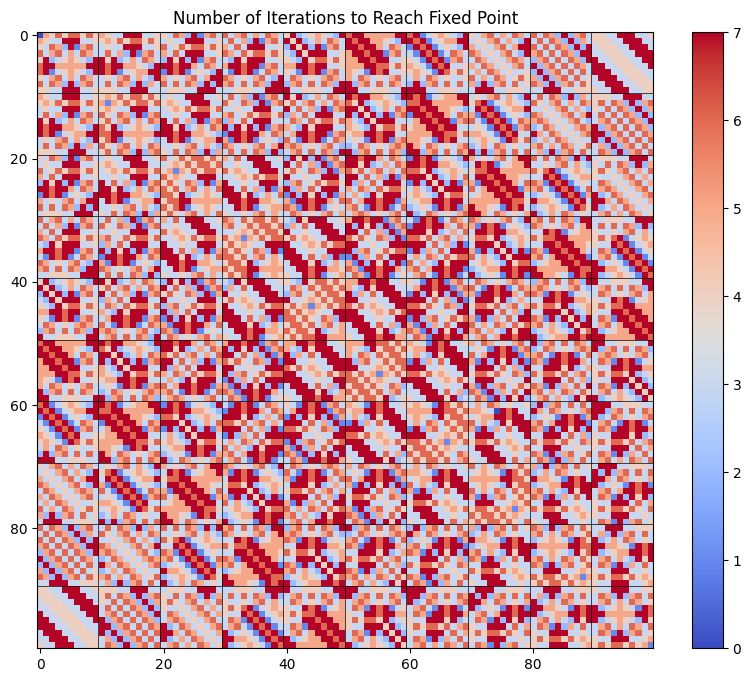

In [9]:
# reshape counts into a 2D grid
data = np.array([0] + kaprekar_iteration_counts(4))  
reshaped_data = data.reshape((100, 100))

# plot the grid
plt.figure(figsize=(10, 8))
plt.imshow(reshaped_data, cmap='coolwarm', vmin=0, vmax=7, aspect='equal')
plt.title("Number of Iterations to Reach Fixed Point")
plt.colorbar();

# grid lines
plt.gca().set_xticks(np.arange(10-0.6, 90, 10), minor=True)
plt.gca().set_yticks(np.arange(10-0.6, 90, 10), minor=True)
plt.gca().grid(which='minor', color='black', linewidth=0.5, alpha=1)
plt.gca().tick_params(axis='both', which='minor', length=0);

In [10]:
# Reinitialize the array with all numbers from 1 to 9999, with zero-padding considered
numbers = np.arange(1, 10000)

# Re-run the process with the updated range of numbers
row_data = []
# results_df = pd.DataFrame(columns=['Iteration', 'Unique Values', 'Unique Sorted Values'])

# Perform up to 7 iterations of the Kaprekar procedure
for i in range(0, 8):
    numbers = np.array([ x for x in numbers if not identical_digits(x, 4) ])
    unique_values_count = len(np.unique(numbers))
    unique_sorted_values_count = len(np.unique([sort_digits(n, 4) for n in numbers]))
    numbers_mean = np.mean(numbers)
    numbers_std = np.std(numbers)
    numbers_max = np.max(numbers)
    numbers_min = np.min(numbers)
                         
    # Record the counts in the DataFrame
    row_data.append({
        'Iteration': i,
        'Unique Values': unique_values_count,
        'Unique Sorted Values': unique_sorted_values_count,
        'Mean': numbers_mean,
        'Std. Dev.': numbers_std,
        'Max': numbers_max,
        'Min': numbers_min,
    })
    # Apply the Kaprekar function to each element in the array
    numbers = np.vectorize(k)(numbers)

# Display the DataFrame
results_df = pd.DataFrame(row_data)
results_df


,Iteration,Unique Values,Unique Sorted Values,Mean,Std. Dev.,Max,Min
0,0,9990,705,4999.500000,2886.430596,9998,1
1,1,54,30,6113.562162,2044.904197,9801,999
2,2,20,17,6643.637838,1747.398797,9621,1089
3,3,14,12,5843.443243,1721.184042,9621,1998
4,4,10,8,5894.248649,1622.963317,8532,1998
5,5,7,5,6182.259459,1230.052241,8532,3087
6,6,4,2,6197.740541,997.305005,8532,4176
7,7,1,1,6174.000000,0.000000,6174,6174


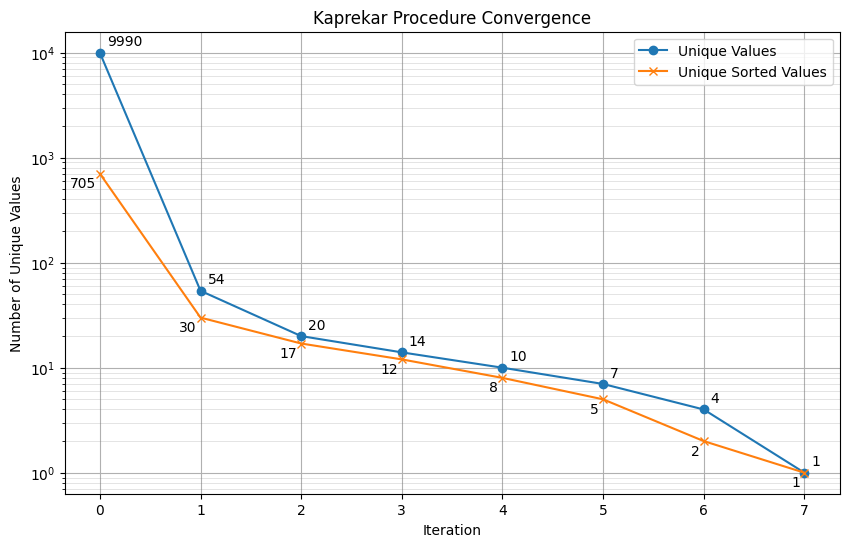

In [11]:
# Plotting the 'Unique Values' and 'Unique Sorted Values' on the same chart
plt.figure(figsize=(10, 6))

plt.plot(results_df['Iteration'], results_df['Unique Values'], label='Unique Values', marker='o')
plt.plot(results_df['Iteration'], results_df['Unique Sorted Values'], label='Unique Sorted Values', marker='x')

plt.title('Kaprekar Procedure Convergence')
plt.xlabel('Iteration')
plt.ylabel('Number of Unique Values')
plt.xticks(results_df['Iteration'].astype(int))  # Ensure x-ticks are integer values
plt.yscale('log')
plt.legend()
plt.grid(which='major')
plt.grid(which='minor', linewidth='0.5', color='grey', alpha=0.3)

# data labels
for i, data_label in enumerate(results_df['Unique Values']):
    plt.annotate(
        data_label,
        xy=(results_df['Iteration'][i], results_df['Unique Values'][i]),
        textcoords="offset points", xytext=(5, 5), ha='left')

for i, data_label in enumerate(results_df['Unique Sorted Values']):
    plt.annotate(
        data_label,
        xy=(results_df['Iteration'][i], results_df['Unique Sorted Values'][i]),
        textcoords="offset points", 
        xytext=(-3, -10),
        ha='right')

# Show the plot
plt.show()


In [12]:
np.unique(numbers)

array([6174])

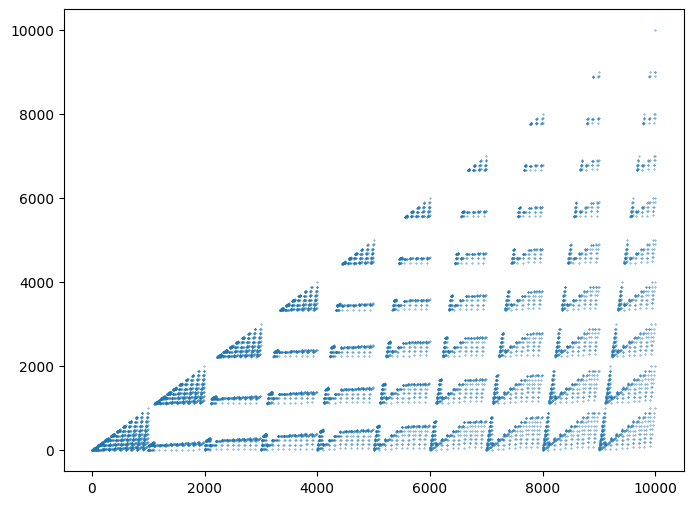

In [13]:
xs = np.arange(0, 10_000)
ys = sorted_numbers = [ int(sort_digits(x, 4)) for x in xs ]

plt.figure(figsize=(8, 6))
plt.scatter(xs, ys, s=0.1)


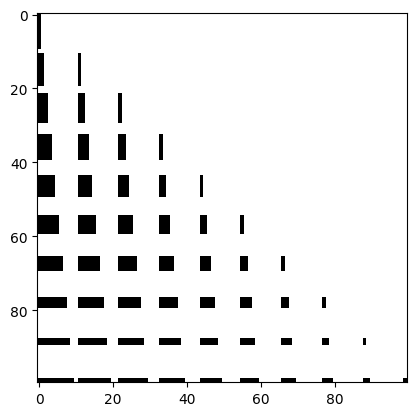

In [14]:
digits_are_sorted_grid = np.zeros(shape=(100, 100))
for y in ys:
    digits_are_sorted_grid[y % 100][y // 100] = 1
plt.imshow(digits_are_sorted_grid, cmap='Greys', vmin=0, vmax=1, aspect='equal')

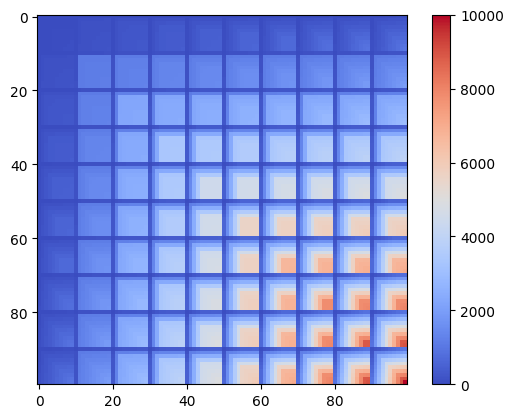

In [15]:
plt.imshow(np.array(ys).reshape( (100, 100) ), cmap='coolwarm', vmin=0, vmax=len(ys), aspect='equal');
plt.colorbar();

In [16]:
def digits_sortedness(n: int, length=4) -> int:
    score = 0
    digits = str(n).zfill(length)
    
    for i in range(1, len(digits)):
        if digits[i] >= digits[i - 1]:
            score += 1
    
    return score

assert digits_sortedness(1234) == 3
assert digits_sortedness(4321) == 0
assert digits_sortedness(3322) == 2
assert digits_sortedness(4398) == 1
assert digits_sortedness(1) == 3

sortedness = np.array([digits_sortedness(n) for n in range(10_000)])
sortedness_grid = sortedness.reshape(100, 100)
sortedness_grid.shape

(100, 100)

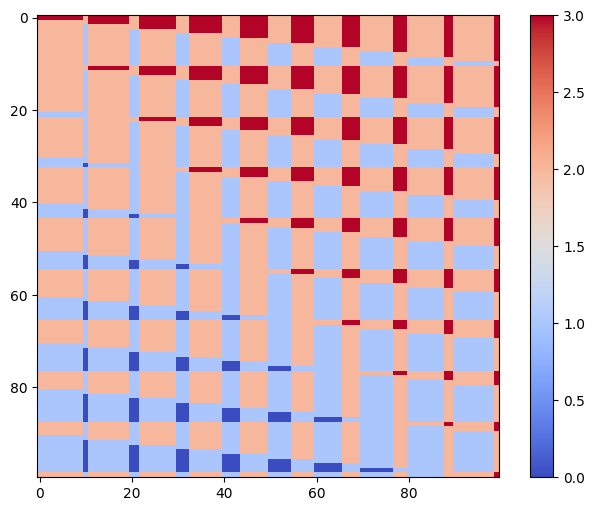

In [17]:
plt.figure(figsize=(8, 6))
plt.imshow(sortedness_grid, cmap='coolwarm', vmin=0, vmax=3, aspect='equal')
plt.colorbar();

In [18]:
# count of numbers where k(n) == 1
len(np.where(data==1)[0])

392

In [19]:
k(3953)

6174

In [20]:
sevens = np.where(data==7)[0]
sevens[ sevens % 100 == 50 ]

array([ 150,  250,  850,  950, 1050, 1250, 1350, 1950, 2050, 2150, 2350,
       2450, 3150, 3250, 3450, 3550, 4250, 4350, 4550, 4650, 5350, 5450,
       6450, 6650, 8050, 9050, 9150, 9950], dtype=int64)

In [21]:
start = np.array([40, 18])
end = np.array([496, 475])
def coord(point):
    length = end - start
    return np.round(100 * (np.array(point) - start)/length)
    
coord(np.array([269, 226]))


array([50., 46.])

In [22]:
# diagonal
#streak = [4945, 5046, 5147, 5248, 5349, 5450]
streak = [5046, 5147, 5248, 5349]
print('sorted:', [sort_digits(n, 4) for n in streak])
for index in streak:
    assert data[index] == 7

print([ k(n) for n in streak ])
print([ k(k(n)) for n in streak ])
print([ k(k(k(n))) for n in streak ])
print([ k(k(k(k(n)))) for n in streak ])
print([ k(k(k(k(k(n))))) for n in streak ])
print([ k(k(k(k(k(k(n)))))) for n in streak ])
print([ k(k(k(k(k(k(k(n))))))) for n in streak ])

sorted: ['0456', '1457', '2458', '3459']
[6084, 6084, 6084, 6084]
[8172, 8172, 8172, 8172]
[7443, 7443, 7443, 7443]
[3996, 3996, 3996, 3996]
[6264, 6264, 6264, 6264]
[4176, 4176, 4176, 4176]
[6174, 6174, 6174, 6174]


In [23]:
#  7541
# -1457
# -----
#  6084

#  8542
# -2458
# -----
#  6048

In [24]:
k(9543) 

6084

In [25]:
xs = sorted_valid_numbers
ukx = np.unique([k(x) for x in xs])
print(ukx.shape)
ukx

(54,)


array([ 999, 1089, 1998, 2088, 2178, 2997, 3087, 3177, 3267, 3996, 4086,
       4176, 4266, 4356, 4995, 5085, 5175, 5265, 5355, 5445, 5994, 6084,
       6174, 6264, 6354, 6444, 6534, 6993, 7083, 7173, 7263, 7353, 7443,
       7533, 7623, 7992, 8082, 8172, 8262, 8352, 8442, 8532, 8622, 8712,
       8991, 9081, 9171, 9261, 9351, 9441, 9531, 9621, 9711, 9801])

In [26]:
np.unique([int(sort_digits(k(x), 4)) for x in xs])

array([ 189,  288,  378,  468,  558,  999, 1179, 1269, 1278, 1359, 1377,
       1449, 1467, 1557, 1899, 2268, 2358, 2367, 2448, 2466, 2556, 2799,
       3357, 3447, 3456, 3555, 3699, 4446, 4455, 4599])

In [27]:
ukkx = np.unique([ k(x) for x in ukx ])
print(ukkx.shape)
print(np.unique([int(sort_digits(x, 4)) for x in ukkx]).shape)
print('missing:', set(ukkx) - set(ukx))

(20,)
(17,)
missing: set()


In [28]:
arrows = set()
for x in ukx:
    arrows.add(f'{x} -> {k(x)}')

print('digraph G {')
for arrow in arrows:
    print('   ', arrow)
print('}')

digraph G {
    6444 -> 1998
    9171 -> 8532
    9711 -> 8532
    2088 -> 8532
    8352 -> 6174
    9351 -> 8172
    999 -> 8991
    5175 -> 5994
    8172 -> 7443
    3177 -> 6354
    6993 -> 6264
    7353 -> 4176
    5994 -> 5355
    6264 -> 4176
    4266 -> 4176
    4086 -> 8172
    6174 -> 6174
    8532 -> 6174
    5085 -> 7992
    4176 -> 6174
    2178 -> 7443
    7263 -> 5265
    9621 -> 8352
    3996 -> 6264
    1089 -> 9621
    3087 -> 8352
    8442 -> 5994
    9801 -> 9621
    9261 -> 8352
    9081 -> 9621
    1998 -> 8082
    2997 -> 7173
    9531 -> 8172
    7992 -> 7173
    5355 -> 1998
    6084 -> 8172
    8622 -> 6354
    7083 -> 8352
    7443 -> 3996
    7623 -> 5265
    5265 -> 3996
    8991 -> 8082
    6354 -> 3087
    6534 -> 3087
    4356 -> 3087
    4995 -> 5355
    8082 -> 8532
    3267 -> 5265
    5445 -> 1089
    7533 -> 4176
    8712 -> 7443
    7173 -> 6354
    8262 -> 6354
    9441 -> 7992
}


In [29]:
import colorsys

def hsl_to_rgb(h, s, l):
    """Convert HSL color space to RGB color space."""
    r, g, b = colorsys.hls_to_rgb(h, l, s)
    return int(r * 255), int(g * 255), int(b * 255)

def generate_pastel_colors(count=32):
    """Generate pastel colors in RGB format."""
    colors = []
    for i in range(count):
        hue = i / count  # Vary the hue between 0 and 1
        saturation = 0.5  # Fixed saturation
        lightness = 0.7  # Fixed lightness for pastel tones
        rgb = hsl_to_rgb(hue, saturation, lightness)
        colors.append(f'#{rgb[0]:02x}{rgb[1]:02x}{rgb[2]:02x}')  # Convert to hex format
    return colors

# Generate 20 unique pastel colors
pastel_colors = generate_pastel_colors()
print(pastel_colors)

['#d88c8c', '#d89a8c', '#d8a88c', '#d8b78c', '#d8c58c', '#d8d38c', '#cfd88c', '#c0d88c', '#b2d88c', '#a4d88c', '#95d88c', '#8cd891', '#8cd89f', '#8cd8ad', '#8cd8bc', '#8cd8ca', '#8cd8d8', '#8ccad8', '#8cbcd8', '#8cadd8', '#8c9fd8', '#8c91d8', '#958cd8', '#a48cd8', '#b28cd8', '#c08cd8', '#cf8cd8', '#d88cd3', '#d88cc5', '#d88cb7', '#d88ca8', '#d88c9a']


In [30]:
# Function to calculate the sum of digits
def sum_of_digits(n):
    return sum(int(d) for d in str(n))

# Initialize the unique colors set and the arrows set
unique_colors = set()
arrows = set()

# Generate the 'ukx' array with unique Kaprekar values
ukx = np.unique([k(x, 4) for x in range(1, 10000) if not identical_digits(x, 4)])

# Map each unique color number to a color
color_map = {}

# Predefined color list
#color_list = ['red', 'green', 'blue', 'yellow', 'orange', 'purple', 'pink', 'cyan', 'magenta', 'gold']
color_list = pastel_colors

for x in ukx:
    color_number = sort_digits(x, 4)
    if color_number not in color_map:
        color_map[color_number] = color_list[len(color_map) % len(color_list)]
    color = color_map[color_number]
    arrows.add(f'{x} [fillcolor="{color}", style=filled]')
    arrows.add(f'{x} -> {k(x)}')

# Create and print the graph definition
print('digraph G {')
for arrow in arrows:
    print('   ', arrow)
print('}')


digraph G {
    9081 [fillcolor="#d89a8c", style=filled]
    9261 [fillcolor="#d88cd3", style=filled]
    7992 [fillcolor="#d8d38c", style=filled]
    8172 -> 7443
    3267 [fillcolor="#b2d88c", style=filled]
    8991 [fillcolor="#d8a88c", style=filled]
    7443 [fillcolor="#958cd8", style=filled]
    4086 -> 8172
    4176 [fillcolor="#8cd891", style=filled]
    4176 -> 6174
    6444 [fillcolor="#8c9fd8", style=filled]
    8172 [fillcolor="#d8c58c", style=filled]
    8712 [fillcolor="#d8c58c", style=filled]
    3087 -> 8352
    8442 -> 5994
    3177 [fillcolor="#c0d88c", style=filled]
    8262 [fillcolor="#a48cd8", style=filled]
    5445 [fillcolor="#8cadd8", style=filled]
    4266 [fillcolor="#8cd89f", style=filled]
    6084 -> 8172
    8442 [fillcolor="#c08cd8", style=filled]
    7173 [fillcolor="#c0d88c", style=filled]
    8262 -> 6354
    9081 -> 9621
    9171 [fillcolor="#cf8cd8", style=filled]
    2997 [fillcolor="#d8d38c", style=filled]
    5994 [fillcolor="#8cd8bc", style=fille

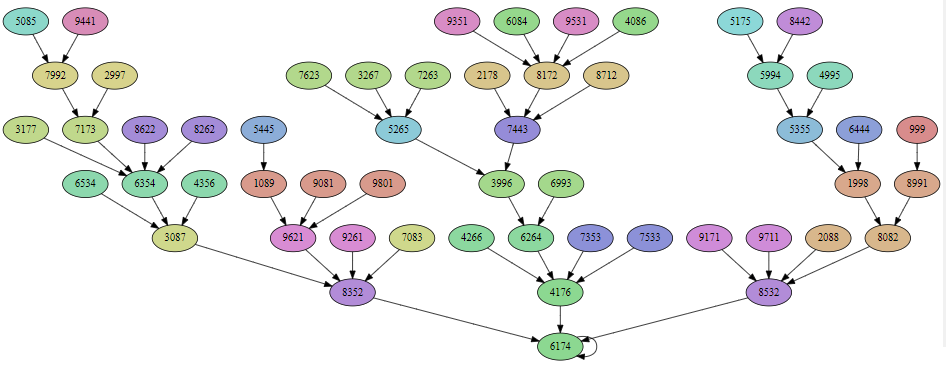

In [31]:
# Display an image from a local file
Image(filename='data/kaprekar_graph_colored.png')

In [32]:
k(k(2024))

6264

In [33]:
def fpow(function, value, iterations):
    """Apply a function repeatedly to a value."""
    for _ in range(iterations):
        value = function(value)
    return value


frames = []
xs = np.arange(0, 10_000)
for iteration in range(1, 7):
    kx = np.array([fpow(k, x, iteration) for x in xs])
    unique_values = np.unique(kx)
    frame_data = np.array([np.where(unique_values == value)[0][0] for value in kx])
    frames.append(frame_data.reshape((100, 100)))


In [34]:
maximum_frame_value = max(np.max(frame) for frame in frames)
figure, axis = plt.subplots(figsize=(10, 8), dpi=100)
image = axis.imshow(
    frames[0],
    cmap="rainbow",
    vmin=0,
    vmax=maximum_frame_value,
    aspect="equal",
)

axis.set_xticks(np.arange(9.4, 90, 10), minor=True)
axis.set_yticks(np.arange(9.4, 90, 10), minor=True)
axis.grid(which="minor", color="black", linewidth=0.5, alpha=1)
axis.tick_params(axis="both", which="minor", length=0)
figure.colorbar(image, ax=axis)


def update(frame_number: int) -> tuple:
    """Display one precomputed Kaprekar iteration frame."""
    image.set_data(frames[frame_number])
    axis.set_title(f"Unique Values After {frame_number + 1} Iteration(s)")
    return (image,)


animation = FuncAnimation(
    figure,
    update,
    frames=len(frames),
    interval=1000,
    blit=True,
    repeat=True,
    cache_frame_data=False,
)
plt.close(figure)
HTML(animation.to_jshtml(fps=1))


In [35]:
def are_diagonal(x, y, length=4) -> bool:
    if length != 4:
        raise NotImplementedError("only implemented for length=4 so far.")
        
    # Sort the digits of each number
    sorted_x = sort_digits(x, length=length)
    sorted_y = sort_digits(y, length=length)
    
    # Compute the differences between the sorted digits
    differences = [int(b) - int(a) for a, b in zip(sorted_x, sorted_y)]
    for d in differences:
        if abs(d) != 1:
            return False
    
    return all([ d1 == d2 for (d1, d2) in zip(differences, differences[::-1]) ])

# Example usage:
# are_diagonal(6084, 9351) should return True
assert are_diagonal(6084, 9351)
assert not are_diagonal(1234, 5678)

In [36]:
def find_diagonal_neighbors(x, length=4):
    if length != 4:
        raise NotImplementedError("only implemented for length=4 so far.")
        
    all_numbers = np.arange(1, 10000)
    valid_numbers = np.array([ num for num in all_numbers if not identical_digits(num, length) ])
    diagonal_neighbors = [ y for y in valid_numbers if are_diagonal(x, y, length) ]
    return diagonal_neighbors

In [37]:
find_diagonal_neighbors(1234)

[123,
 132,
 213,
 231,
 312,
 321,
 1023,
 1032,
 1203,
 1230,
 1302,
 1320,
 2013,
 2031,
 2103,
 2130,
 2301,
 2310,
 2345,
 2354,
 2435,
 2453,
 2534,
 2543,
 3012,
 3021,
 3102,
 3120,
 3201,
 3210,
 3245,
 3254,
 3425,
 3452,
 3524,
 3542,
 4235,
 4253,
 4325,
 4352,
 4523,
 4532,
 5234,
 5243,
 5324,
 5342,
 5423,
 5432]

In [38]:
all_numbers = np.arange(1, 10000)
valid_numbers = np.array([ num for num in all_numbers if not identical_digits(num, 4) ])
sorted_valid_numbers = np.unique(np.array([ int(sort_digits(x, 4)[::-1]) for x in valid_numbers ]))
len(sorted_valid_numbers)

705

In [39]:
count_misses = 0
count_hits = 0
neighbors = []

for z in sorted_valid_numbers:
    kz = k(z)
    for w in sorted_valid_numbers:
        if w < z and are_diagonal(z, w):
            kw = k(w)
            
            neighbors.append({ 'z': z, 'w': w, 'k(z)': kz, 'k(w)': kw })
            if kz != kw:
                print(f'z={z} w={w} k(z)={kz} k(w)={kw}')
                count_misses += 1
            else:
                count_hits += 1
                
print(f'hits: {count_hits}, misses: {count_misses}')
neighbors_df = pd.DataFrame(neighbors)

hits: 696, misses: 0


In [40]:
neighbors_df.sample(20)

,z,w,k(z),k(w)
647,9884,8773,4995,4995
410,8775,7664,2997,2997
258,7753,6642,4176,4176
84,6221,5110,4995,4995
325,8541,7430,7083,7083
548,9661,8550,7992,7992
281,8311,7200,7173,7173
167,7322,6211,5085,5085
392,8742,7631,6264,6264
441,8881,7770,6993,6993


In [41]:
assert are_diagonal(6084, 9351)
assert are_diagonal(8442, 5175)
assert are_diagonal(9441, 5085)
assert are_diagonal(7443, 5265)
assert are_diagonal(4266, 7533)
assert are_diagonal(8082, 9171)
assert are_diagonal(9261, 3087)
assert are_diagonal(7173, 8262)
assert are_diagonal(9441, 5085)
assert are_diagonal(8442, 5175)

In [42]:
N = 100_000
count_neighbors = 0
for i in range(N):
    x = np.random.choice(valid_numbers, replace=True)
    y = np.random.choice(valid_numbers, replace=True)
    count_neighbors += int(are_diagonal(x, y))
p_neighbors = count_neighbors / N
print(f'Percent Diagonal Neighbors: {p_neighbors*100:0.2f}%')   


Percent Diagonal Neighbors: 0.32%


In [43]:
N = 10_000
count_neighbors = 0
k_valid_numbers = np.unique(np.array([ k(x) for x in valid_numbers]))
print(len(k_valid_numbers))
for i in range(N):
    x = np.random.choice(k_valid_numbers, replace=True)
    y = np.random.choice(k_valid_numbers, replace=True)
    count_neighbors += int(are_diagonal(x, y))
p_neighbors = count_neighbors / N
print(f'Percent Diagonal Neighbors: {p_neighbors*100:0.2f}%')  

54
Percent Diagonal Neighbors: 2.11%


In [44]:
1 - (1 - 0.023)**54

0.7153531115320197

In [45]:
1 - (1 - 0.0032)**54

0.15892721017895906

In [46]:
# # digit histograms
# xs = valid_numbers
# for i in range(0, 8):
#     all_digits = list(''.join( str(x) for x in xs ))

#     # Create a list of counts for each digit from 0 to 9
#     counts = [all_digits.count(str(digit)) for digit in range(10)]   
#     plt.bar(range(10), counts)
#     plt.xlabel('Digit')
#     plt.ylabel('Frequency')
#     plt.title(f'Distribution of Digits after {i} Iteration(s)')
#     plt.xticks(range(10), [str(digit) for digit in range(10)])  # Set x-ticks to be the digits from 0 to 9
#     plt.show()
    
#     xs = np.unique(np.array([ k(x) for x in xs ]))

In [47]:
np.mean(np.array([ k(x) for x in valid_numbers]))

6113.562162162162